# MNIST handwritten Digit Classification CNN

In [30]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
import tensorflow as tf
from tensorflow.keras import datasets
from tensorflow.math import confusion_matrix


In [31]:
(X_train, y_train), (X_test, y_test) = datasets.mnist.load_data()

print("Train data shape:",X_train.shape)
print("Test data shape : ",X_test.shape)

Train data shape: (60000, 28, 28)
Test data shape :  (10000, 28, 28)


In [32]:
type(X_train)  
print(X_train[10].shape)

(28, 28)


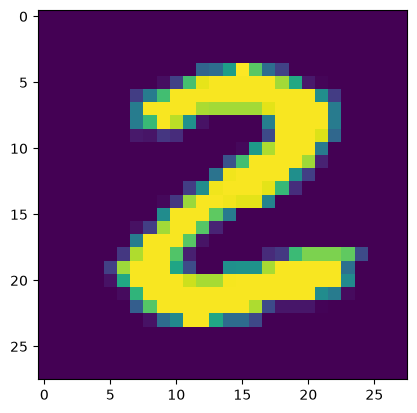

2


In [33]:
## Displaying the image
plt.imshow(X_train[25])
plt.show()

## print the corresponding label
print(y_train[25])

Image Lables


In [34]:
print(y_train.shape,y_test.shape)

(60000,) (10000,)


In [35]:
# check Unique value is in y Train
print(np.unique(y_train))

# check unique values in Y_test
print(np.unique(y_test))

[0 1 2 3 4 5 6 7 8 9]
[0 1 2 3 4 5 6 7 8 9]


* we can use these labels as such or we can also apply One hot Encoding
* all the images have same dimensions in this dataset, if not, we have to resize all the images   to a common dimension 

In [36]:
## scaling the values 
X_train = X_train/255
X_test = X_test/255

In [37]:
print(X_train[10])


[[0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.        ]
 [0.         0.         0.         0.         0.         0.
  0.         0.         0.         0.         0.         0.
  0.         0.    

Building the Neural Network

In [38]:
from tensorflow.keras import activations
# Setting up the layers of the neural network
model = tf.keras.Sequential([
       tf.keras.layers.Flatten(input_shape=(28,28)),
       tf.keras.layers.Dense(128,activation='relu'),
       tf.keras.layers.Dense(64,activation='relu'),
       tf.keras.layers.Dense(10,activation='softmax') 
])

c:\Users\harish\Desktop\CNN_Projects\cnn_env\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [39]:
# Compiling the nueral network

model.compile(optimizer='adam',
    loss = 'sparse_categorical_crossentropy',
    metrics=['accuracy']
       )

In [40]:
## training the nueral network

model.fit(X_train, y_train, epochs=10)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9284 - loss: 0.2419
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9687 - loss: 0.1004
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9769 - loss: 0.0717
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9832 - loss: 0.0534
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9858 - loss: 0.0440
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9893 - loss: 0.0334
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9902 - loss: 0.0288
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9916 - loss: 0.0261
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9932 - loss: 0.0211
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9941 - loss: 0.0185


Training Data Accuracy = 95.36%

### Accuracy on Test Data

In [41]:
loss, accuracy = model.evaluate(X_test,y_test)
print(accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9786 - loss: 0.0826
0.978600025177002


Test data Accyracy = 95.27%

In [42]:
print(X_test.shape)

(10000, 28, 28)


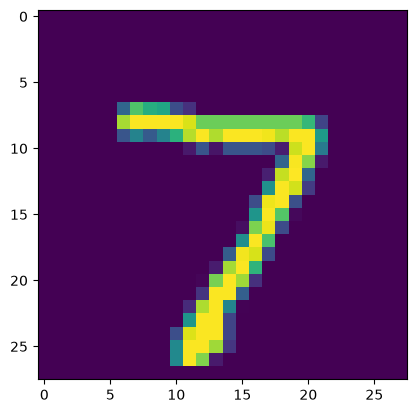

In [43]:
# First data point in X_test
plt.imshow(X_test[0])
plt.show()

In [44]:
print(y_test[0])

7


In [45]:
y_pred = model.predict(X_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


In [46]:
print(y_pred.shape)

(10000, 10)


In [47]:
print(y_pred[0])

[1.0036311e-07 4.7841542e-07 1.3885708e-06 5.0726749e-06 1.1208130e-11
 2.6738596e-11 3.8954117e-14 9.9999273e-01 6.0057260e-08 8.3774026e-08]


model.predict() gives the prediction probablity of each class for the particular data point

In [48]:
# converting the prediction probablities to class label

label_for_first_image = np.argmax(y_pred[0])
print(label_for_first_image)

7


In [49]:
## Converting the prediction probablity to class level for all test data point

y_pred_labels = []

for i in y_pred:
    max_index = int(np.argmax(i))
    y_pred_labels.append(max_index)

print(y_pred_labels)

[7, 2, 1, 0, 4, 1, 4, 9, 5, 9, 0, 6, 9, 0, 1, 5, 9, 7, 3, 4, 9, 6, 6, 5, 4, 0, 7, 4, 0, 1, 3, 1, 3, 4, 7, 2, 7, 1, 2, 1, 1, 7, 4, 2, 3, 5, 1, 2, 4, 4, 6, 3, 5, 5, 6, 0, 4, 1, 9, 5, 7, 8, 9, 3, 7, 4, 6, 4, 3, 0, 7, 0, 2, 9, 1, 7, 3, 2, 9, 7, 7, 6, 2, 7, 8, 4, 7, 3, 6, 1, 3, 6, 9, 3, 1, 4, 1, 7, 6, 9, 6, 0, 5, 4, 9, 9, 2, 1, 9, 4, 8, 7, 3, 9, 7, 9, 4, 4, 9, 2, 5, 4, 7, 6, 7, 9, 0, 5, 8, 5, 6, 6, 5, 7, 8, 1, 0, 1, 6, 4, 6, 7, 3, 1, 7, 1, 8, 2, 0, 2, 9, 8, 5, 5, 1, 5, 6, 0, 3, 4, 4, 6, 5, 4, 6, 5, 4, 5, 1, 4, 4, 7, 2, 3, 2, 7, 1, 8, 1, 8, 1, 8, 5, 0, 8, 9, 2, 5, 0, 1, 1, 1, 0, 9, 0, 3, 1, 6, 4, 2, 3, 6, 1, 1, 1, 3, 9, 5, 2, 9, 4, 5, 9, 3, 9, 0, 3, 6, 5, 5, 7, 2, 2, 7, 1, 2, 8, 4, 1, 7, 3, 3, 8, 8, 7, 9, 2, 2, 4, 1, 5, 9, 8, 7, 2, 3, 0, 2, 4, 2, 4, 1, 9, 5, 7, 7, 2, 8, 2, 6, 8, 5, 7, 7, 9, 1, 8, 1, 8, 0, 3, 0, 1, 9, 3, 4, 1, 8, 2, 1, 2, 9, 7, 5, 9, 2, 6, 4, 1, 5, 8, 2, 9, 2, 0, 4, 0, 0, 2, 8, 4, 7, 1, 2, 4, 0, 2, 7, 4, 3, 3, 0, 0, 3, 1, 9, 6, 5, 2, 5, 9, 7, 9, 3, 0, 4, 2, 0, 7, 1, 1, 2, 1, 

ytest -> true lables
y_pred_lables -> Predicted Lables

Confusion Matrix

In [50]:
conf_mat = confusion_matrix(y_test, y_pred_labels)

In [51]:
print(conf_mat)

tf.Tensor(
[[ 974    0    1    0    0    0    3    1    1    0]
 [   0 1126    3    1    0    1    2    1    1    0]
 [   1    4  999    2    3    0    3    6   14    0]
 [   0    0    8  988    0    3    0    5    3    3]
 [   1    1    2    1  959    0    5    2    0   11]
 [   2    0    0   14    1  860    4    0    9    2]
 [   2    2    1    1    3    2  947    0    0    0]
 [   4    5    8    1    1    0    1 1005    2    1]
 [   5    1    3    1    4    2    1    6  947    4]
 [   3    2    0    4    5    1    1   11    1  981]], shape=(10, 10), dtype=int32)


Text(0.5, 47.833333333333314, 'Predicted Labels')

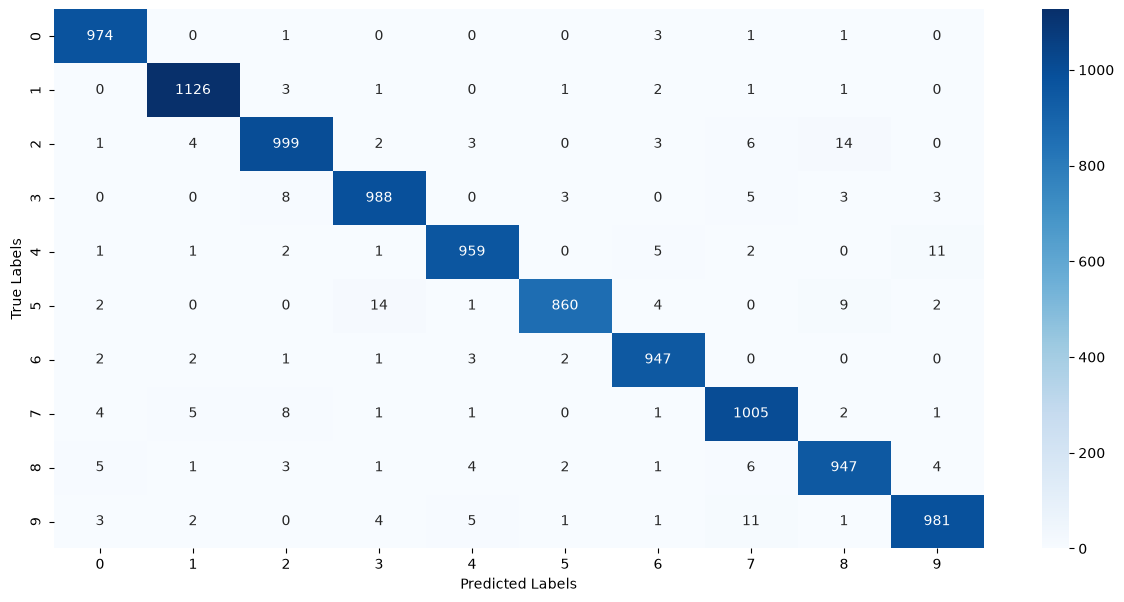

In [52]:
plt.figure(figsize=(15,7))
sns.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues')
plt.ylabel('True Labels')
plt.xlabel('Predicted Labels')

Building a Predictive System

In [53]:
input_image_path = '5.png'

input_image = cv2.imread(input_image_path)

In [54]:
type(input_image)

numpy.ndarray

In [55]:
print(input_image)

[[[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]

 ...

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]

 [[255 255 255]
  [255 255 255]
  [255 255 255]
  ...
  [255 255 255]
  [255 255 255]
  [255 255 255]]]


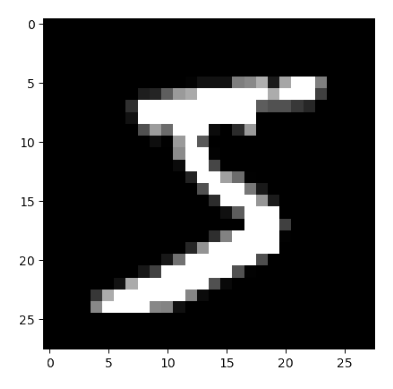

In [56]:
plt.imshow(cv2.cvtColor(input_image, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

In [57]:
input_image.shape

(413, 417, 3)

In [58]:
grayscale = cv2.cvtColor(input_image, cv2.COLOR_RGB2GRAY)

In [59]:
input_image_resize = cv2.resize(grayscale, (28,28))

In [60]:
input_image_resize.shape

(28, 28)

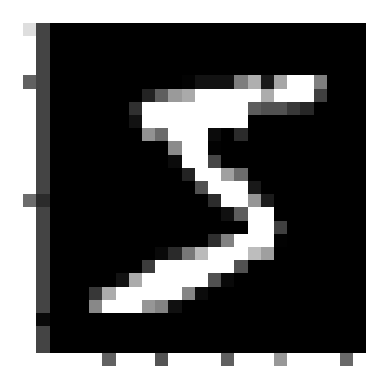

In [61]:
plt.imshow(cv2.cvtColor(input_image_resize, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

In [62]:
# scaled the input image
input_image_resize = input_image_resize / 255


In [63]:
type(input_image_resize)

numpy.ndarray

In [64]:
image_reshape = np.reshape(input_image_resize,[1,28,28])

In [65]:
input_prediction = model.predict(image_reshape)
print(input_prediction)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
[[4.9880451e-23 5.4190134e-17 3.7623127e-14 3.7805737e-08 5.6067167e-29
  3.5147620e-18 3.3845183e-38 1.0000000e+00 1.1560056e-29 3.5696698e-10]]


In [66]:
input_pred_label = np.argmax(input_prediction)

In [67]:
print(input_pred_label)

7


Predictive System

# USING CNN ALGORITHM

In [68]:
model_cnn = tf.keras.Sequential([
    tf.keras.layers.Reshape((28,28,1), input_shape=(28,28)),

    # 1st Convolutional Block
    tf.keras.layers.Conv2D(32, kernel_size=(3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(pool_size=(2,2)),

    # 2nd Convolutional Block
    tf.keras.layers.Conv2D(64, kernel_size=(3,3), activation='relu'),
    tf.keras.layers.MaxPooling2D(pool_size=(2,2)),

    # Flatten & Dense Layers
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dropout(0.25),

   tf.keras.layers.Dense(64, activation='relu'),
   tf.keras.layers.Dense(10, activation='softmax')

])

model_cnn.summary()

c:\Users\harish\Desktop\CNN_Projects\cnn_env\Lib\site-packages\keras\src\layers\reshaping\reshape.py:39: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ reshape (Reshape)               │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [69]:
## Compilation

model_cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [70]:
## Training
history_cnn = model_cnn.fit(X_train, y_train, epochs=10, batch_size=64, 
validation_split=0.1)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.9376 - loss: 0.2038 - val_accuracy: 0.9828 - val_loss: 0.0590
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9796 - loss: 0.0659 - val_accuracy: 0.9875 - val_loss: 0.0421
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 10ms/step - accuracy: 0.9854 - loss: 0.0470 - val_accuracy: 0.9890 - val_loss: 0.0384
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.9879 - loss: 0.0371 - val_accuracy: 0.9898 - val_loss: 0.0353
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9905 - loss: 0.0311 - val_accuracy: 0.9872 - val_loss: 0.0409
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.9916 - loss: 0.0253 - val_accuracy: 0.9912 - val_loss: 0.0352
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.9925 - loss: 0.0232 - val_accuracy: 0.9927 - val_loss: 0.0286
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9936 - loss: 0.0196 - val_accurac

In [71]:
## evaluate and Compare
loss_cnn, accuracy_cnn = model_cnn.evaluate(X_test,  y_test)
print(f"ANN (model) Test Accuracy : {accuracy * 100:.2f}%")
print(f"CNN (model_cnn) Test Accuracy : {accuracy_cnn * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9920 - loss: 0.0281
ANN (model) Test Accuracy : 97.86%
CNN (model_cnn) Test Accuracy : 99.20%


### Prediction

In [72]:
input_image_path = input('Path of the image to be predicted : ')
input_image = cv2.imread(input_image_path)

plt.imshow(cv2.cvtColor(input_image, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

grayscale = cv2.cvtColor(input_image, cv2.COLOR_BGR2GRAY)
input_image_resize = cv2.resize(grayscale, (28,28))
input_image_scaled = input_image_resize / 255.0
image_reshape = np.reshape(input_image_scaled,[1,28,28])

# Predict with your best model (model_cnn)
prediction = model_cnn.predict(image_reshape)
pred_label = np.argmax(prediction)

print(f"The Predicted Digit is : {pred_label}" )

error: OpenCV(5.0.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\color.cpp:199: error: (-215:Assertion failed) !_src.empty() in function 'cv::cvtColor'
